# Chapter 1, Problem 21 — timelike ⇒ same place in some frame; spacelike ⇒ same time in some frame

**Problem (paraphrased).**
- **(a)** Show that if two events are timelike separated, there is a Lorentz frame in which they occur at the same point (same spatial coordinates).
- **(b)** Similarly, show that if two events are spacelike separated, there is a Lorentz frame in which they are simultaneous.

**Setup.** Let the events be separated by $(\Delta t, \Delta x, \Delta y, \Delta z)$ in some frame $\mathcal O$, with spatial separation $\Delta r = \sqrt{\Delta x^2 + \Delta y^2 + \Delta z^2}$ and interval $\Delta s^2 = -\Delta t^2 + \Delta r^2$.

**Step 0 — rotate the spatial axes.** A rotation of $\mathcal O$'s spatial axes is a perfectly good change of inertial frame (it leaves $t$ and $\Delta r$ unchanged). Rotate so the $x$ axis points along the spatial separation. Then
$$
\Delta x = \Delta r \geq 0,\qquad \Delta y = \Delta z = 0 .
$$
Now we only need a boost along $x$, Eq. (1.12):
$$
\Delta\bar t = \gamma(\Delta t - v\Delta x),\qquad \Delta\bar x = \gamma(\Delta x - v\Delta t),\qquad \Delta\bar y = \Delta\bar z = 0 .
$$
The only requirement on the boost is $|v| < 1$.

## (a) Timelike: $\Delta s^2 < 0 \iff \Delta r < |\Delta t|$

We want $\Delta\bar x = 0$:
$$
\gamma(\Delta x - v\Delta t) = 0 \quad\Longrightarrow\quad v = \frac{\Delta x}{\Delta t} = \frac{\Delta r}{\Delta t}.
$$
(If $\Delta r = 0$ the events are already at the same point; take $v=0$.)

**Is this an allowed frame?** Timelike separation means $\Delta r^2 < \Delta t^2$, i.e. $|v| = \Delta r/|\Delta t| < 1$ ✓. So $\bar{\mathcal O}$ exists: it's the frame of an observer who travels uniformly from the first event to the second. Since $\Delta\bar y = \Delta\bar z = 0$ too, the events occur at the **same spatial point** in $\bar{\mathcal O}$. $\blacksquare$

**The time separation in that frame.** By invariance, $-\Delta\bar t^2 = \Delta s^2$, so
$$
|\Delta\bar t| = \sqrt{-\Delta s^2} = \text{proper time between the events}.
$$
Direct check: $\Delta\bar t = \gamma(\Delta t - v\Delta r) = \gamma\,\Delta t\,(1 - v^2) = \Delta t/\gamma$, which has the same sign as $\Delta t$. A boost can never reverse the time order of timelike-separated events.

## (b) Spacelike: $\Delta s^2 > 0 \iff |\Delta t| < \Delta r$

We want $\Delta\bar t = 0$:
$$
\gamma(\Delta t - v\Delta x) = 0 \quad\Longrightarrow\quad v = \frac{\Delta t}{\Delta x} = \frac{\Delta t}{\Delta r}.
$$
(Here $\Delta r > 0$, since $\Delta r^2 > \Delta t^2 \geq 0$.)

**Allowed?** Spacelike separation means $|\Delta t| < \Delta r$, so $|v| < 1$ ✓. In $\bar{\mathcal O}$ the events are **simultaneous**. $\blacksquare$

**The spatial separation in that frame:** $|\Delta\bar x| = \sqrt{\Delta s^2}$, the proper distance. Direct check: $\Delta\bar x = \gamma(\Delta r - v\Delta t) = \gamma\Delta r(1 - v^2) = \Delta r/\gamma$.

**Bonus — time order is not invariant here.** Any $|v| < 1$ is allowed, and $\Delta\bar t = \gamma(\Delta t - v\Delta r)$ changes sign at $v = \Delta t/\Delta r$. Frames with $v$ on either side of it disagree about which event came first. That's why no signal can connect spacelike-separated events: causality would break.

## Why neither works for null separation

For $\Delta s^2 = 0$, both formulas give $|v| = 1$: no inertial frame can make null-separated events simultaneous or co-located. Light has no rest frame.

## A more general view (no rotation needed)

For a boost with velocity vector $\vec v$, $\Delta\bar t = \gamma(\Delta t - \vec v\cdot\Delta\vec r)$. For (a) the choice is $\vec v = \Delta\vec r/\Delta t$, which is unique. For (b) *any* $\vec v$ with $\vec v\cdot\Delta\vec r = \Delta t$ and $|\vec v| < 1$ works — a whole family of frames, of which $\vec v \parallel \Delta\vec r$ with the smallest speed is the one above.

In [1]:
import sympy as sp
from schutz_gr import lorentz
dt, dr = sp.symbols("Delta_t Delta_r", real=True)

v_a = dr/dt
tb, xb = lorentz(dt, dr, v_a)
print("(a) v = Δr/Δt:  Δx̄ =", sp.simplify(xb), ",  Δt̄² =", sp.simplify(tb**2), " = Δt² − Δr² = −Δs²")
v_b = dt/dr
tb, xb = lorentz(dt, dr, v_b)
print("(b) v = Δt/Δr:  Δt̄ =", sp.simplify(tb), ",  Δx̄² =", sp.simplify(xb**2), " = Δr² − Δt² = Δs²")

(a) v = Δr/Δt:  Δx̄ = 0 ,  Δt̄² = -Delta_r**2 + Delta_t**2  = Δt² − Δr² = −Δs²
(b) v = Δt/Δr:  Δt̄ = 0 ,  Δx̄² = Delta_r**2 - Delta_t**2  = Δr² − Δt² = Δs²


In [2]:
import numpy as np
from schutz_gr import boost_matrix, interval

def rotate_to_x(d):
    # spatial rotation taking Δr̂ to the x axis (Rodrigues formula), acting on (t, x, y, z)
    r = d[1:]; n = r / np.linalg.norm(r); ex = np.array([1.0, 0, 0])
    k = np.cross(n, ex); s = np.linalg.norm(k); c = n @ ex
    if s < 1e-12:
        Rm = np.eye(3) if c > 0 else np.diag([-1.0, -1.0, 1.0])
    else:
        k /= s; K = np.array([[0, -k[2], k[1]], [k[2], 0, -k[0]], [-k[1], k[0], 0]])
        Rm = np.eye(3) + s*K + (1 - c)*K @ K
    out = np.eye(4); out[1:, 1:] = Rm
    return out

for label, d in (("(a) timelike ", np.array([5.0, 1.0, 2.0, -2.0])),
                 ("(b) spacelike", np.array([1.0, 2.0, -1.0, 2.0]))):
    R = rotate_to_x(d); d1 = R @ d
    v = d1[1]/d1[0] if interval(d) < 0 else d1[0]/d1[1]
    db = boost_matrix(v) @ d1
    print(f"{label}: Δx = {d},  Δs² = {interval(d):+.2f}")
    print(f"   after rotation: {np.round(d1, 6)};  boost v = {v:+.4f};  in new frame: {np.round(db, 6)}  (Δs² = {interval(db):+.2f})")

(a) timelike : Δx = [ 5.  1.  2. -2.],  Δs² = -16.00
   after rotation: [ 5.  3.  0. -0.];  boost v = +0.6000;  in new frame: [ 4.  0.  0. -0.]  (Δs² = -16.00)
(b) spacelike: Δx = [ 1.  2. -1.  2.],  Δs² = +8.00
   after rotation: [ 1.  3.  0. -0.];  boost v = +0.3333;  in new frame: [ 0.        2.828427  0.       -0.      ]  (Δs² = +8.00)


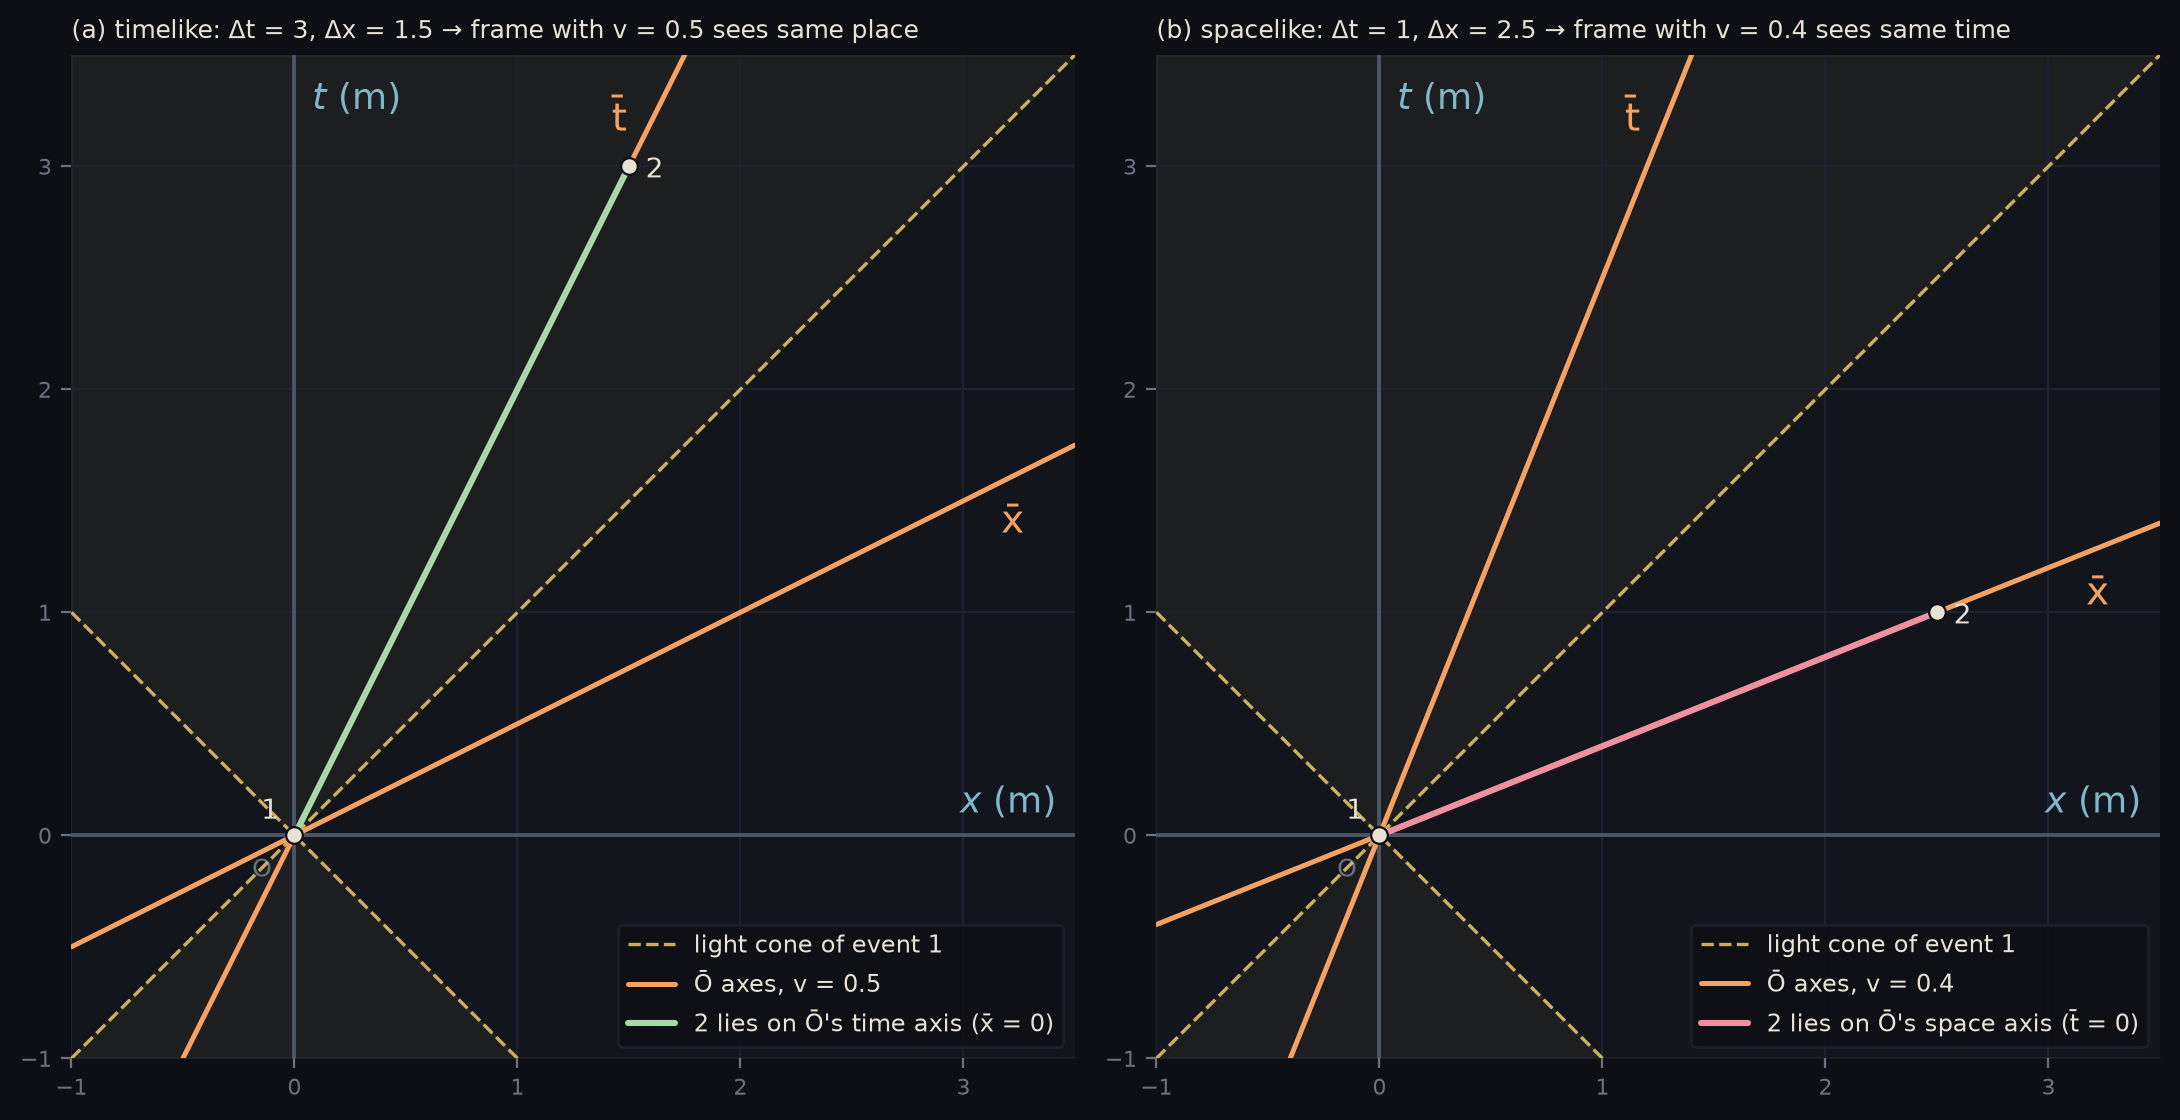

In [3]:
from schutz_gr.diagrams import SpacetimeDiagram, COLORS
%config InlineBackend.figure_format = 'retina'
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(11, 5.5)); fig.patch.set_facecolor(COLORS["bg"])
cases = [("(a) timelike: Δt = 3, Δx = 1.5 → frame with v = 0.5 sees same place", (3.0, 1.5)),
         ("(b) spacelike: Δt = 1, Δx = 2.5 → frame with v = 0.4 sees same time", (1.0, 2.5))]
for ax, (title, (T2, X2)) in zip(axs, cases):
    d = SpacetimeDiagram(xlim=(-1, 3.5), tlim=(-1, 3.5), title=None, ax=ax)
    ax.set_title(title, color=COLORS["text"], fontsize=9, loc="left")
    d.light_cone(label="light cone of event 1", color="gold")
    timelike = T2 > X2
    v = X2/T2 if timelike else T2/X2
    d.boosted_axes(v, color="amber", label=f"Ō axes, v = {v:g}")
    d.event(0, 0, name="1", offset=(-12, 6)); d.event(T2, X2, name="2", offset=(6, -4))
    if timelike:
        d.line([0, X2], [0, T2], color="green", lw=2.2, label="2 lies on Ō's time axis (x̄ = 0)")
    else:
        d.line([0, X2], [0, T2], color="rose", lw=2.2, label="2 lies on Ō's space axis (t̄ = 0)")
    d.legend(loc="lower right")
plt.tight_layout(); plt.show()